In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import joblib
import shap

print("Libraries imported successfully!")

Libraries imported successfully!


Load dataset and saved model

In [2]:
df = pd.read_csv("../data/raw/ai4i2020.csv")

model_pipeline = joblib.load(
    "../models/failure_xgboost.joblib"
)

print("Dataset shape:", df.shape)
print("Model loaded successfully!")

Dataset shape: (10000, 14)
Model loaded successfully!


In [3]:
from sklearn.model_selection import train_test_split

features = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[features].copy()
y = df["Machine failure"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Test samples:", len(X_test))

Test samples: 2000


Extract preprocessing and XGBoost

In [4]:
preprocessor = model_pipeline.named_steps["preprocessor"]
xgb_model = model_pipeline.named_steps["classifier"]

print(type(preprocessor))
print(type(xgb_model))

<class 'sklearn.compose._column_transformer.ColumnTransformer'>
<class 'xgboost.sklearn.XGBClassifier'>


Transform the data
SHAP should explain what the actual XGBoost model receives after preprocessing:

In [5]:
X_test_transformed = preprocessor.transform(X_test)

print(
    "Transformed test shape:",
    X_test_transformed.shape
)

Transformed test shape: (2000, 8)


Get the actual transformed feature names

In [9]:
# Get transformed feature names
original_feature_names = preprocessor.get_feature_names_out()

# Create XGBoost/SHAP-safe names
safe_feature_names = [
    str(name)
    .replace("[", "(")
    .replace("]", ")")
    .replace("<", "_")
    for name in original_feature_names
]

print("Original names:")
print(original_feature_names)

print("\nSHAP-safe names:")
print(safe_feature_names)

Original names:
['num__Air temperature [K]' 'num__Process temperature [K]'
 'num__Rotational speed [rpm]' 'num__Torque [Nm]' 'num__Tool wear [min]'
 'cat__Type_H' 'cat__Type_L' 'cat__Type_M']

SHAP-safe names:
['num__Air temperature (K)', 'num__Process temperature (K)', 'num__Rotational speed (rpm)', 'num__Torque (Nm)', 'num__Tool wear (min)', 'cat__Type_H', 'cat__Type_L', 'cat__Type_M']


Now create a DataFrame:

In [12]:
X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=safe_feature_names,
    index=X_test.index
)

X_test_shap.head()

,num__Air temperature (K),num__Process temperature (K),num__Rotational speed (rpm),num__Torque (Nm),num__Tool wear (min),cat__Type_H,cat__Type_L,cat__Type_M
2997,0.247681,-0.139294,-1.073963,2.265378,0.712410,0.0,1.0,0.0
4871,1.850310,1.618248,-0.145641,0.009646,0.429427,0.0,1.0,0.0
3858,1.249324,0.942270,0.108543,-0.239882,1.592802,0.0,1.0,0.0
951,-2.206344,-2.505215,-0.167744,-0.419543,-0.749670,1.0,0.0,0.0
6463,0.247681,-0.004098,-1.002129,2.035812,-0.089376,1.0,0.0,0.0


Create the SHAP explainer
for xgboost

In [13]:
explainer = shap.TreeExplainer(xgb_model)

shap_values = explainer(
    X_test_shap,
    check_additivity=False
)

print("SHAP values shape:", shap_values.values.shape)

SHAP values shape: (2000, 8)


Then generate global feature importance

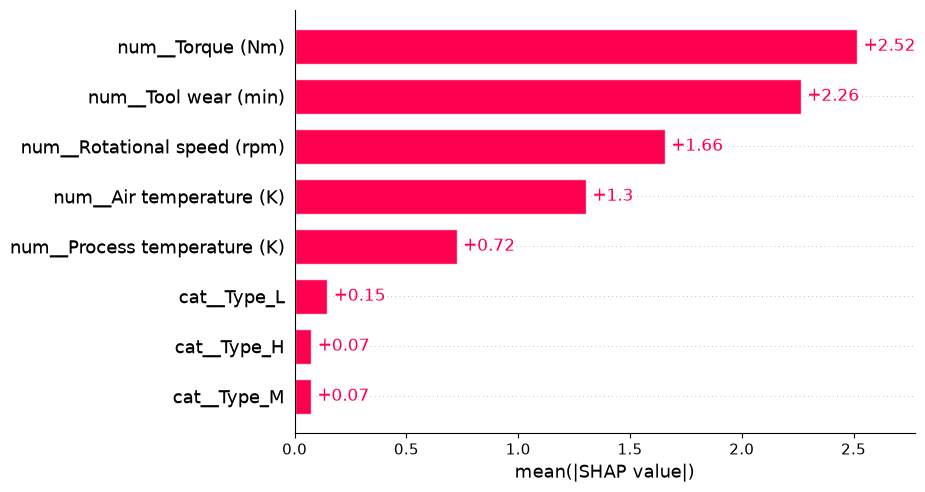

In [14]:
shap.plots.bar(
    shap_values,
    max_display=8
)

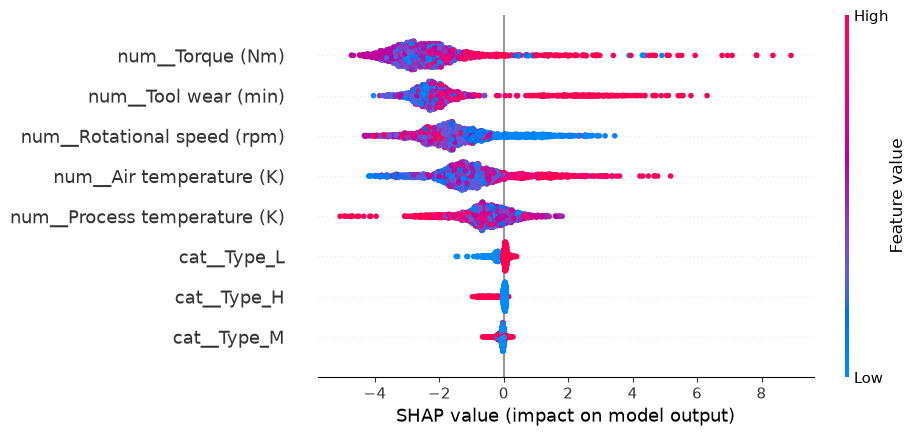

In [15]:
shap.plots.beeswarm(
    shap_values,
    max_display=8
)

In [16]:
display_names = [
    "Air Temperature (K)",
    "Process Temperature (K)",
    "Rotational Speed (rpm)",
    "Torque (Nm)",
    "Tool Wear (min)",
    "Type H",
    "Type L",
    "Type M"
]

shap_values.feature_names = display_names

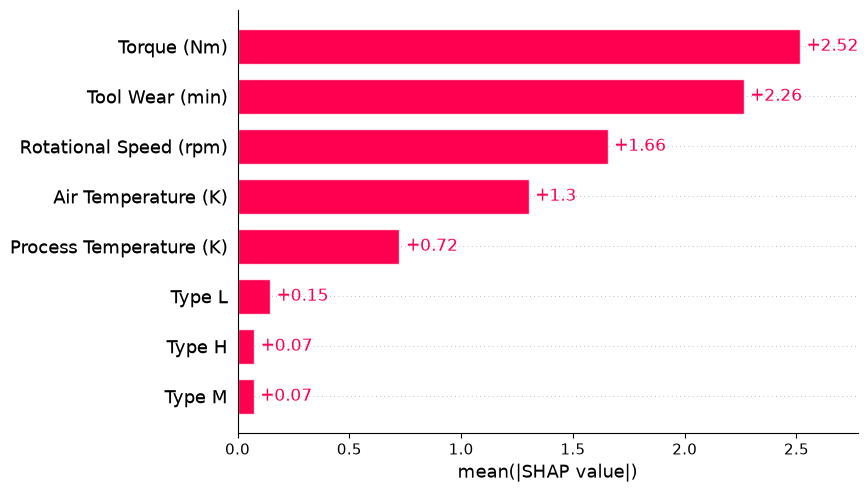

In [17]:
shap.plots.bar(
    shap_values,
    max_display=8
)

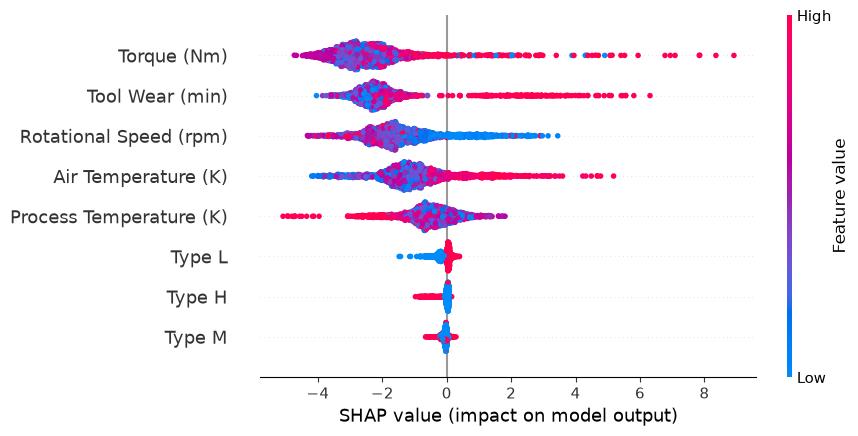

In [18]:
shap.plots.beeswarm(
    shap_values,
    max_display=8
)

Get predictions using our final threshold

In [19]:
FINAL_THRESHOLD = 0.29

failure_probabilities = model_pipeline.predict_proba(
    X_test
)[:, 1]

failure_predictions = (
    failure_probabilities >= FINAL_THRESHOLD
).astype(int)

print("Predictions created successfully!")

Predictions created successfully!


Find correctly detected failures

In [20]:
detected_failure_positions = np.where(
    (failure_predictions == 1) &
    (y_test.to_numpy() == 1)
)[0]

print(
    "Correctly detected failures:",
    len(detected_failure_positions)
)

Correctly detected failures: 56


Select one real failure

In [21]:
sample_position = detected_failure_positions[0]

sample_original_index = X_test.index[sample_position]

print("Test position:", sample_position)
print("Original dataset index:", sample_original_index)
print(
    "Failure score:",
    failure_probabilities[sample_position]
)

print("\nActual class:",
      y_test.iloc[sample_position])

print("Predicted class:",
      failure_predictions[sample_position])

X_test.iloc[[sample_position]]

Test position: 21
Original dataset index: 1391
Failure score: 0.9939726

Actual class: 1
Predicted class: 1


,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min]
1391,L,298.9,310.2,2737,8.8,142


SHAP waterfall plot

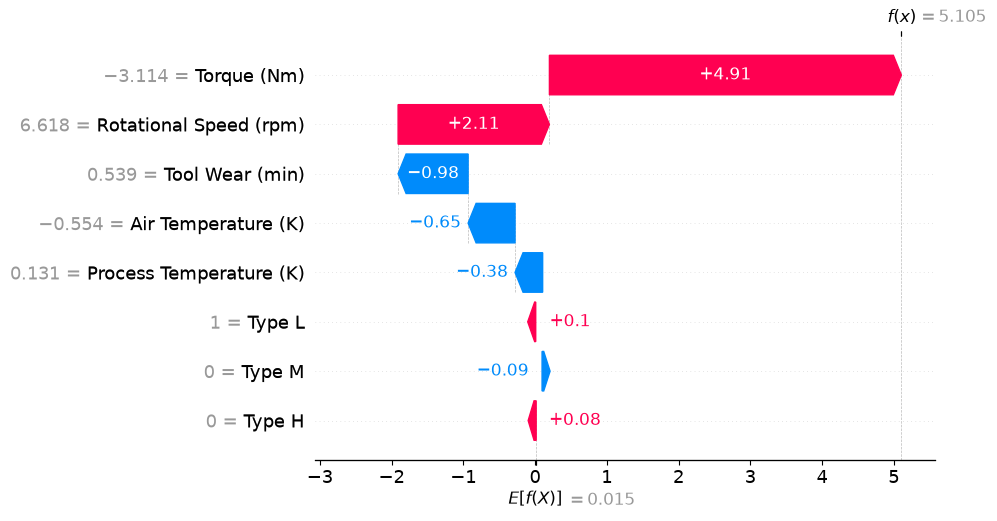

In [22]:
shap.plots.waterfall(
    shap_values[sample_position],
    max_display=8
)

This is an important visualization for the project.
It explains one specific prediction.
The plot will show features pushing the XGBoost output:
toward FAILURE
      ↑
      │
      │ positive SHAP contribution
──────┼────────────────
      │
      │ negative SHAP contribution
      ↓
toward NORMAL

Do not interpret the SHAP value itself as a percentage probability.

Extract explanation numerically

In [23]:
sample_shap = pd.DataFrame({
    "Feature": shap_values.feature_names,
    "SHAP Value": shap_values.values[sample_position]
})

sample_shap["Absolute Importance"] = (
    sample_shap["SHAP Value"].abs()
)

sample_shap = sample_shap.sort_values(
    "Absolute Importance",
    ascending=False
)

sample_shap

,Feature,SHAP Value,Absolute Importance
3,Torque (Nm),4.905341,4.905341
2,Rotational Speed (rpm),2.108754,2.108754
4,Tool Wear (min),-0.975710,0.975710
0,Air Temperature (K),-0.654228,0.654228
1,Process Temperature (K),-0.384801,0.384801
6,Type L,0.096727,0.096727
7,Type M,-0.088560,0.088560
5,Type H,0.082413,0.082413


Separate risk-increasing and risk-reducing factors

In [24]:
risk_factors = sample_shap[
    sample_shap["SHAP Value"] > 0
].sort_values(
    "SHAP Value",
    ascending=False
)

protective_factors = sample_shap[
    sample_shap["SHAP Value"] < 0
].sort_values(
    "SHAP Value"
)

print("TOP FACTORS PUSHING TOWARD FAILURE:")
print(
    risk_factors[
        ["Feature", "SHAP Value"]
    ].head(3)
)

print("\nTOP FACTORS PUSHING TOWARD NORMAL:")
print(
    protective_factors[
        ["Feature", "SHAP Value"]
    ].head(3)
)

TOP FACTORS PUSHING TOWARD FAILURE:
                  Feature  SHAP Value
3             Torque (Nm)    4.905341
2  Rotational Speed (rpm)    2.108754
6                  Type L    0.096727

TOP FACTORS PUSHING TOWARD NORMAL:
                   Feature  SHAP Value
4          Tool Wear (min)   -0.975710
0      Air Temperature (K)   -0.654228
1  Process Temperature (K)   -0.384801


SHAP is used to explain which input features contributed most strongly to each model prediction.